<a href="https://colab.research.google.com/github/kangyeson/AI-Class/blob/main/1109/stock_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [15]:
# !pip install finance-datareader
import FinanceDataReader as fdr
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [16]:
samsung = fdr.DataReader('005930', '2016')
print(samsung)

              Open    High     Low   Close    Volume    Change
Date                                                          
2016-01-04   25200   25200   24100   24100    306939 -0.043651
2016-01-05   24040   24360   23720   24160    216002  0.002490
2016-01-06   24160   24160   23360   23500    366752 -0.027318
2016-01-07   23320   23660   23020   23260    282388 -0.010213
2016-01-08   23260   23720   23260   23420    257763  0.006879
...            ...     ...     ...     ...       ...       ...
2026-11-03  220500  223000  217000  222000  13391670 -0.034783
2026-11-04  226500  228000  208000  221500  22248738 -0.002252
2026-11-05  213000  213500  199800  201500  24657743 -0.090293
2026-11-06  180000  196500  179200  193500  35516270 -0.039702
2026-11-09  187200  195400  187000  193300  12112218 -0.001034

[2660 rows x 6 columns]


In [17]:
openValues = samsung[['Open']]

In [18]:
# 8:2 비율로 데이터 분리
split = int(len(openValues) * 0.8)

train_data = openValues[:split]
test_data = openValues[split:]

In [19]:
# 학습 데이터만으로 Scaler 학습
scaler = MinMaxScaler(feature_range=(0, 1))
train_data = scaler.fit_transform(train_data)

In [20]:
# 테스트 데이터는 학습 데이터의 Scaler로 변환
test_data = scaler.transform(test_data)

In [21]:
def make_sample(data, window):
    train = []
    target = []
    for i in range(len(data)-window):
        train.append(data[i:i+window])
        target.append(data[i+window])
    return np.array(train), np.array(target)

# 학습 데이터 생성
X_train, y_train = make_sample(train_data, 30)

# 테스트 데이터 생성
X_test, y_test = make_sample(test_data, 30)

In [22]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LSTM

model = Sequential()
model.add(LSTM(16,
               input_shape=(X_train.shape[1], 1),
               activation='tanh',
               return_sequences=False)
)
model.add(Dense(1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [23]:
model.compile(optimizer='adam', loss='mean_squared_error')

In [24]:
model.fit(X_train, y_train, epochs=100, batch_size=16)

pred = model.predict(X_test)

Epoch 1/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - loss: 0.0730
Epoch 2/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0015
Epoch 3/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0011
Epoch 4/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0010    
Epoch 5/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0010    
Epoch 6/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0010    
Epoch 7/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.9718e-04
Epoch 8/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.9930e-04
Epoch 9/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.8248e-04
Epoch 10/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.1776e-04
Epoch 11/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.4533e-04
Epoch 12/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.0996e-04
Epoch 13/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 9.1679e-04
Epoch 14/100
132/132 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 8.7486e-04

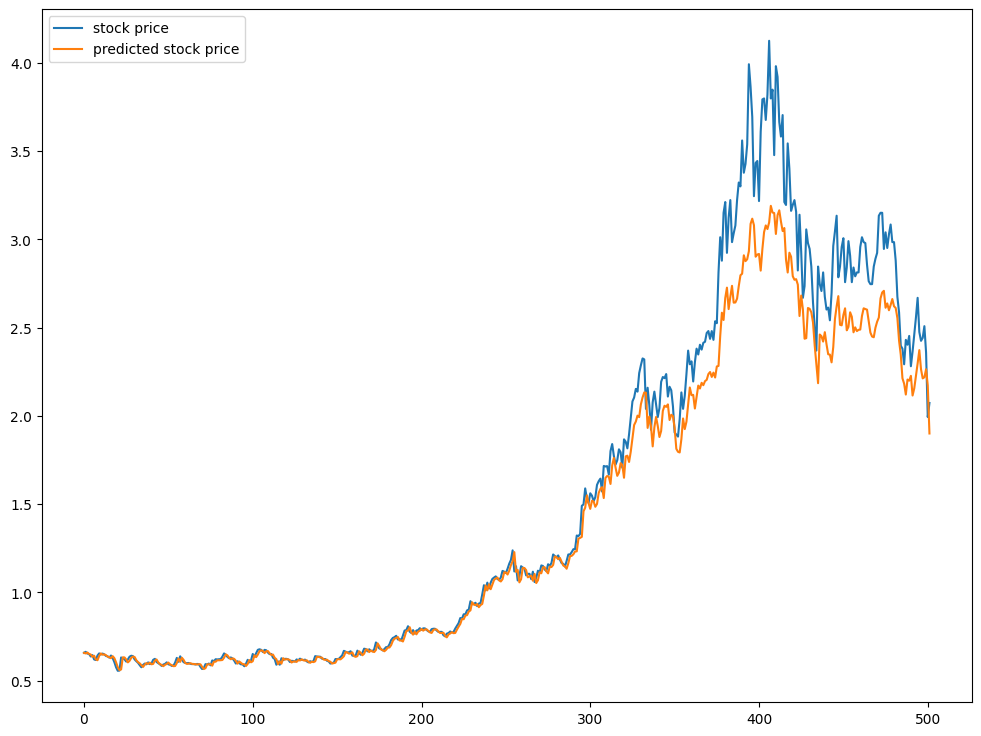

In [25]:
plt.figure(figsize=(12, 9))
plt.plot(y_test, label='stock price')
plt.plot(pred, label='predicted stock price')
plt.legend()
plt.show()